# Aujourd'hui, c'est normal ?
## Analyse historique des températures quotidiennes — Paris-Montsouris

### 1. Objectif

Étudier les températures minimales (TN) et maximales (TX)
quotidiennes de Paris-Montsouris sur une période historique
potentielle de 1872 à 2026.

Cette étude vise à :
- Vérifier la continuité des archives.
- Mesurer la disponibilité et la qualité des observations.
- Étudier l'évolution des températures sur le temps long.
- Construire des classements historiques à date identique.
- Préparer les données pour une datavisualisation interactive.

### 2. Sources

**Producteur :** Météo-France

**Jeu de données :** Données climatologiques de base quotidiennes

**Station :** Paris-Montsouris (75114001)

**Archives :**
- Avant 1950
- 1950–2024
- 2025–2026

**Licence :** Licence Ouverte 2.0

### 3. Précautions méthodologiques

La présence d'observations anciennes ne garantit pas leur
homogénéité climatique.

Nous examinerons les valeurs manquantes, les codes qualité,
les éventuelles ruptures de série et les limites des comparaisons
historiques.

Une température maximale quotidienne ne doit pas être
comparée directement à une température horaire instantanée.

## 4. Chargement des archives quotidiennes

Les données sont réparties en trois fichiers compressés couvrant
les périodes avant 1950, 1950–2024 et 2025–2026.

Nous sélectionnons la station Paris-Montsouris (75114001)
et les variables nécessaires à notre étude :

- `AAAAMMJJ` : date de l'observation.
- `TN` : température minimale quotidienne.
- `TX` : température maximale quotidienne.
- `QTN` et `QTX` : indicateurs de qualité associés.

L'objectif est de vérifier la couverture temporelle et la
disponibilité des températures dans chaque archive.

In [1]:
from pathlib import Path
import pandas as pd

DATA_DIR = Path.cwd().parent / "data" / "quotidiennes"
STATION_ID = "75114001"

fichiers = sorted(DATA_DIR.glob("*.csv.gz"))

assert len(fichiers) == 3, "Les trois archives sont introuvables."

resultats = []
observations = []

for fichier in fichiers:
    df = pd.read_csv(
        fichier,
        sep=";",
        compression="gzip",
        dtype={"NUM_POSTE": str},
        usecols=["NUM_POSTE", "AAAAMMJJ", "TN", "TX", "QTN", "QTX"]
    )

    paris = df.loc[df["NUM_POSTE"] == STATION_ID].copy()

    paris["date"] = pd.to_datetime(
        paris["AAAAMMJJ"].astype(str),
        format="%Y%m%d"
    )

    resultats.append({
        "Archive": fichier.name,
        "Première date": paris["date"].min(),
        "Dernière date": paris["date"].max(),
        "Journées": len(paris),
        "TN disponibles": paris["TN"].notna().sum(),
        "TX disponibles": paris["TX"].notna().sum()
    })

    observations.append(paris)

bilan = pd.DataFrame(resultats)
display(bilan)

,Archive,Première date,Dernière date,Journées,TN disponibles,TX disponibles
0,Q_75_avant-1949_RR-T-Vent.csv.gz,1872-06-17,1949-12-31,28321,28301,28310
1,Q_75_latest-2025-2026_RR-T-Vent.csv.gz,2025-01-01,2026-11-11,680,680,680
2,Q_75_previous-1950-2024_RR-T-Vent.csv.gz,1950-01-01,2024-12-31,27394,27394,27394


## 5. Contrôle de la continuité historique

Les trois archives sont réunies afin de vérifier :

- L'absence de dates dupliquées.
- La présence de toutes les journées calendaires.
- Le nombre de températures manquantes.
- Les éventuelles interruptions dans la série.

Cette vérification est indispensable avant de construire
des classements historiques sur plus d'un siècle.

In [2]:
# Réunir les trois archives
meteo = pd.concat(observations, ignore_index=True)

# Trier les observations chronologiquement
meteo = meteo.sort_values("date").reset_index(drop=True)

# Vérifier les doublons
doublons = meteo["date"].duplicated().sum()

# Construire le calendrier théorique complet
calendrier = pd.date_range(
    start=meteo["date"].min(),
    end=meteo["date"].max(),
    freq="D"
)

# Identifier les journées absentes
dates_manquantes = calendrier.difference(
    pd.DatetimeIndex(meteo["date"])
)

print(f"Première observation : {meteo['date'].min():%d/%m/%Y}")
print(f"Dernière observation : {meteo['date'].max():%d/%m/%Y}")
print(f"Observations : {len(meteo):,}")
print(f"Doublons : {doublons}")
print(f"Journées absentes : {len(dates_manquantes)}")
print(f"TN manquantes : {meteo['TN'].isna().sum()}")
print(f"TX manquantes : {meteo['TX'].isna().sum()}")

Première observation : 17/06/1872
Dernière observation : 11/11/2026
Observations : 56,395
Doublons : 0
Journées absentes : 0
TN manquantes : 20
TX manquantes : 11


## 6. Contrôle des indicateurs de qualité

Les archives contiennent deux indicateurs associés aux températures :

- `QTN` : qualité de la température minimale.
- `QTX` : qualité de la température maximale.

Nous examinons leur répartition et leur évolution dans le temps
avant de définir les observations retenues pour les classements.

La signification exacte des codes sera vérifiée dans la
documentation officielle de Météo-France.

In [3]:
# Répartition globale des codes qualité
qualite = pd.DataFrame({
    "Température minimale (QTN)": meteo["QTN"].value_counts(dropna=False),
    "Température maximale (QTX)": meteo["QTX"].value_counts(dropna=False)
}).fillna(0).astype(int)

display(qualite)

# Répartition par période historique
meteo["periode"] = pd.cut(
    meteo["date"].dt.year,
    bins=[1871, 1899, 1949, 1999, 2026],
    labels=["1872–1899", "1900–1949", "1950–1999", "2000–2026"]
)

display(
    pd.crosstab(meteo["periode"], meteo["QTX"], dropna=False)
)

,Température minimale (QTN),Température maximale (QTX)
1.0,55697,55930
9.0,697,465
NaN,1,0


QTX,1.0,9.0
periode,,
1872–1899,9594,465
1900–1949,18262,0
1950–1999,18262,0
2000–2026,9812,0


### 6.1. Interprétation officielle des codes qualité

Selon la documentation de Météo-France :

- **Code 0 :** donnée protégée, définitivement validée par le climatologue.
- **Code 1 :** donnée validée par contrôle automatique ou par le climatologue.
- **Code 9 :** donnée filtrée, ayant passé les contrôles de premiers niveaux.
- **Code 2 :** donnée douteuse, en cours de vérification.

Les codes 0 et 1 seront retenus pour les classements principaux.
Les codes 9 seront examinés séparément et les codes 2 exclus.

Dans les archives étudiées, les 465 observations QTX = 9
se concentrent entre 1872 et 1899.

**Période de référence provisoire : 1900–2025.**

Cette sélection ne garantit pas à elle seule l'homogénéité
climatique de la série sur le temps long.

**Source :** Météo-France, `Q_descriptif_champs_RR-T-Vent.csv`.

## 7. Classement historique des températures maximales

Nous comparons les températures maximales (TX) relevées
le 14 novembre de chaque année entre 1900 et 2025.

Pour garantir la cohérence du classement :
- Une seule station est étudiée : Paris-Montsouris.
- Les comparaisons portent sur le même jour calendaire.
- Seules les observations de qualité QTX = 0 ou 1 sont retenues.
- L'année 2026 est exclue de la référence historique.

Nous calculons le Top 3 et le classement de chaque année.

Cette analyse est descriptive : elle ne constitue pas
une normale climatologique officielle.

In [4]:
# Paramètres de notre première comparaison
MOIS = 11
JOUR = 14
ANNEE_DEBUT = 1900
ANNEE_FIN = 2025

# Sélection des températures historiques
classement = meteo.loc[
    (meteo["date"].dt.year >= ANNEE_DEBUT)
    & (meteo["date"].dt.year <= ANNEE_FIN)
    & (meteo["date"].dt.month == MOIS)
    & (meteo["date"].dt.day == JOUR)
    & (meteo["QTX"].isin([0, 1]))
    & (meteo["TX"].notna()),
    ["date", "TX"]
].copy()

# Année et classement décroissant
classement["Année"] = classement["date"].dt.year

classement = classement.sort_values(
    ["TX", "Année"],
    ascending=[False, True]
).reset_index(drop=True)

# Les ex aequo partagent le même rang
classement["Rang"] = (
    classement["TX"]
    .rank(method="min", ascending=False)
    .astype(int)
)

# Présentation du résultat
top3 = classement.loc[
    classement["Rang"] <= 3,
    ["Rang", "Année", "TX"]
].rename(columns={"TX": "Température maximale (°C)"})

print(f"Date étudiée : {JOUR:02d}/{MOIS:02d}")
print(f"Période : {ANNEE_DEBUT}–{ANNEE_FIN}")
print(f"Années disponibles : {len(classement)}")
print(f"Années attendues : {ANNEE_FIN - ANNEE_DEBUT + 1}")

display(top3)

Date étudiée : 14/11
Période : 1900–2025
Années disponibles : 126
Années attendues : 126


,Rang,Année,Température maximale (°C)
0,1,2025,19.6
1,2,2020,17.6
2,3,1986,17.2


## 8. Visualisation du classement historique

Nous représentons les températures maximales du 14 novembre
sur 126 années, de 1900 à 2025.

L'objectif est de visualiser leur répartition dans le temps
et de mettre en évidence les trois températures les plus élevées.

Cette première représentation exploratoire servira de base
à une future datavisualisation interactive avec D3.js.

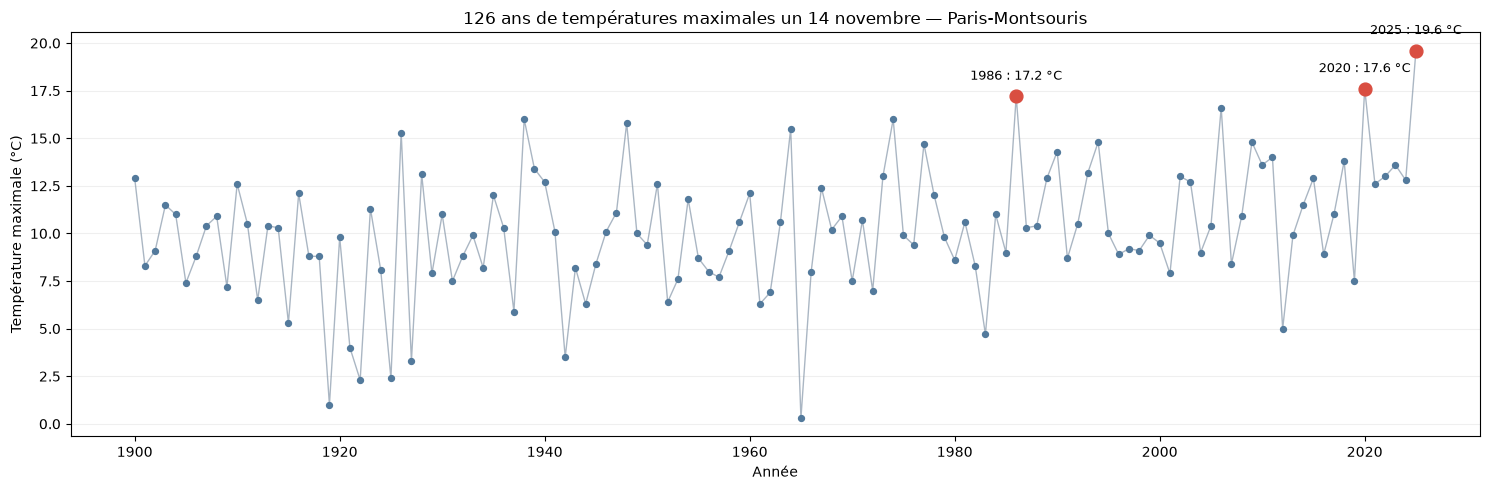

In [5]:
import matplotlib.pyplot as plt

# Présentation chronologique
historique = classement.sort_values("Année")

fig, ax = plt.subplots(figsize=(15, 5))

ax.plot(
    historique["Année"],
    historique["TX"],
    color="#8798AA",
    linewidth=1,
    alpha=0.7
)

ax.scatter(
    historique["Année"],
    historique["TX"],
    color="#537A9C",
    s=18,
    zorder=3
)

# Mettre en évidence les trois premiers rangs
for _, ligne in top3.iterrows():
    ax.scatter(
        ligne["Année"],
        ligne["Température maximale (°C)"],
        color="#D94E41",
        s=85,
        zorder=5
    )

    ax.annotate(
        f'{int(ligne["Année"])} : {ligne["Température maximale (°C)"]:.1f} °C',
        (
            ligne["Année"],
            ligne["Température maximale (°C)"]
        ),
        xytext=(0, 12),
        textcoords="offset points",
        ha="center",
        fontsize=9
    )

ax.set_title(
    "126 ans de températures maximales un 14 novembre — Paris-Montsouris"
)
ax.set_xlabel("Année")
ax.set_ylabel("Température maximale (°C)")
ax.grid(axis="y", alpha=0.2)

plt.tight_layout()
plt.show()

## 9. Distribution historique des températures

Un classement des records ne suffit pas pour déterminer
si une température est habituelle.

Nous étudions la distribution des températures maximales
du 14 novembre entre 1900 et 2025.

Indicateurs :
- Médiane : valeur centrale de la distribution.
- Q1 : premier quartile (25 %).
- Q3 : troisième quartile (75 %).
- Minimum et maximum historiques.

Ces indicateurs décrivent les observations de notre échantillon.
Ils ne constituent pas des normales climatologiques officielles.

In [6]:
# Distribution des températures maximales
temperatures = classement["TX"]

statistiques = pd.DataFrame({
    "Indicateur": [
        "Minimum",
        "Premier quartile (Q1)",
        "Médiane",
        "Troisième quartile (Q3)",
        "Maximum",
        "Moyenne",
        "Écart-type"
    ],
    "Température (°C)": [
        temperatures.min(),
        temperatures.quantile(0.25),
        temperatures.median(),
        temperatures.quantile(0.75),
        temperatures.max(),
        temperatures.mean(),
        temperatures.std()
    ]
})

statistiques["Température (°C)"] = (
    statistiques["Température (°C)"].round(2)
)

display(statistiques)

,Indicateur,Température (°C)
0,Minimum,0.30
1,Premier quartile (Q1),8.30
2,Médiane,10.15
3,Troisième quartile (Q3),12.55
4,Maximum,19.60
5,Moyenne,10.14
6,Écart-type,3.35


## 10. Position d'une température dans l'histoire

Nous calculons la proportion des années historiques
ayant enregistré une température maximale inférieure
à une valeur donnée.

Cette mesure permettra de produire des phrases
compréhensibles par le grand public.

Exemple : « Plus chaud que 85 % des 14 novembre
observés depuis 1900 ».

La comparaison utilise exclusivement des
températures maximales quotidiennes.

In [7]:
# Température fictive pour tester notre futur système
temperature_test = 15.0

# Nombre d'années strictement moins chaudes
annees_moins_chaudes = (
    classement["TX"] < temperature_test
).sum()

# Pourcentage historique
pourcentage = (
    annees_moins_chaudes / len(classement)
) * 100

# Rang théorique si cette température était ajoutée
rang = (
    (classement["TX"] > temperature_test).sum() + 1
)

print(f"Température testée : {temperature_test:.1f} °C")
print(f"Années comparées : {len(classement)}")
print(f"Années moins chaudes : {annees_moins_chaudes}")
print(f"Pourcentage : {pourcentage:.1f} %")
print(f"Rang théorique : {rang} / {len(classement) + 1}")

Température testée : 15.0 °C
Années comparées : 126
Années moins chaudes : 117
Pourcentage : 92.9 %
Rang théorique : 10 / 127


## 11. Généralisation du classement historique

Les calculs précédents ont été validés sur le 14 novembre.

Nous allons maintenant créer une fonction réutilisable
pour analyser n'importe quelle date du calendrier.

La fonction utilisera les observations historiques de 1900
à 2025, en conservant uniquement les températures
validées (QTX = 0 ou 1).

Les résultats serviront ensuite à alimenter l'application
Django et les visualisations D3.js.

In [8]:
def analyser_temperature(mois, jour, temperature, mode="chaud"):
    """
    Compare une température quotidienne à l'historique 1900–2025.

    mode="chaud" : comparaison des maximales TX
    mode="froid" : comparaison des minimales TN
    """

    if mode not in ("chaud", "froid"):
        raise ValueError("Le mode doit être 'chaud' ou 'froid'.")

    colonne = "TX" if mode == "chaud" else "TN"
    qualite = "QTX" if mode == "chaud" else "QTN"

    # Vérifier que le jour et le mois forment une date valide
    from datetime import date
    date(2024, mois, jour)  # 2024 permet le 29 février

    # Sélectionner les observations historiques
    historique = meteo.loc[
        (meteo["date"].dt.year.between(1900, 2025))
        & (meteo["date"].dt.month == mois)
        & (meteo["date"].dt.day == jour)
        & (meteo[qualite].isin([0, 1]))
        & (meteo[colonne].notna()),
        ["date", colonne]
    ].copy()

    if historique.empty:
        raise ValueError("Aucune observation historique disponible.")

    historique["Année"] = historique["date"].dt.year

    # Plus chaud : ordre décroissant
    # Plus froid : ordre croissant
    croissant = mode == "froid"

    historique = historique.sort_values(
        [colonne, "Année"],
        ascending=[croissant, True]
    ).reset_index(drop=True)

    historique["Rang"] = (
        historique[colonne]
        .rank(method="min", ascending=croissant)
        .astype(int)
    )

    # Proportion des années moins extrêmes
    if mode == "chaud":
        moins_extremes = (historique[colonne] < temperature).sum()
        plus_extremes = (historique[colonne] > temperature).sum()
    else:
        moins_extremes = (historique[colonne] > temperature).sum()
        plus_extremes = (historique[colonne] < temperature).sum()

    nombre = len(historique)

    top3 = historique.loc[
        historique["Rang"] <= 3,
        ["Rang", "Année", colonne]
    ].copy()

    return {
        "date": f"{jour:02d}/{mois:02d}",
        "mode": mode,
        "temperature": temperature,
        "annees_comparees": nombre,
        "mediane": round(historique[colonne].median(), 2),
        "pourcentage_moins_extremes": round(
            100 * moins_extremes / nombre, 1
        ),
        "rang_theorique": int(plus_extremes + 1),
        "top3": top3
    }

In [9]:
resultat = analyser_temperature(
    mois=11,
    jour=14,
    temperature=15.0,
    mode="chaud"
)

print("Date :", resultat["date"])
print("Mode :", resultat["mode"])
print("Années comparées :", resultat["annees_comparees"])
print("Médiane :", resultat["mediane"], "°C")
print(
    "Années moins chaudes :",
    resultat["pourcentage_moins_extremes"], "%"
)
print(
    "Rang théorique :",
    resultat["rang_theorique"]
)

display(resultat["top3"])

Date : 14/11
Mode : chaud
Années comparées : 126
Médiane : 10.15 °C
Années moins chaudes : 92.9 %
Rang théorique : 10


,Rang,Année,TX
0,1,2025,19.6
1,2,2020,17.6
2,3,1986,17.2


## 12. Classement des températures minimales

Nous testons le classement des températures minimales
quotidiennes (TN) du 14 novembre, entre 1900 et 2025.

Les températures les plus basses occupent les premiers rangs.

Ce classement mesure les minima les plus froids observés,
et non les températures moyennes des journées.

In [10]:
resultat_froid = analyser_temperature(
    mois=11,
    jour=14,
    temperature=2.0,
    mode="froid"
)

print("Date :", resultat_froid["date"])
print("Mode :", resultat_froid["mode"])
print("Années comparées :", resultat_froid["annees_comparees"])
print("Médiane :", resultat_froid["mediane"], "°C")

print(
    "Années moins froides :",
    resultat_froid["pourcentage_moins_extremes"], "%"
)

print(
    "Rang théorique :",
    resultat_froid["rang_theorique"]
)

display(resultat_froid["top3"])

Date : 14/11
Mode : froid
Années comparées : 126
Médiane : 5.2 °C
Années moins froides : 79.4 %
Rang théorique : 25


,Rang,Année,TN
0,1,1921,-5.4
1,2,1965,-2.2
2,3,1919,-2.0


## 13. Validation du 29 février

Le 29 février n'existe que les années bissextiles.

Nous vérifions que notre fonction :
- sélectionne uniquement les observations du 29 février ;
- calcule les statistiques sur les années disponibles ;
- produit un classement correct ;
- ne suppose pas systématiquement 126 observations.

In [11]:
resultat_bissextile = analyser_temperature(
    mois=2,
    jour=29,
    temperature=12.0,
    mode="chaud"
)

print("Date :", resultat_bissextile["date"])
print("Années comparées :", resultat_bissextile["annees_comparees"])
print("Médiane :", resultat_bissextile["mediane"], "°C")
print(
    "Années moins chaudes :",
    resultat_bissextile["pourcentage_moins_extremes"], "%"
)
print(
    "Rang théorique :",
    resultat_bissextile["rang_theorique"]
)

display(resultat_bissextile["top3"])

Date : 29/02
Années comparées : 31
Médiane : 9.8 °C
Années moins chaudes : 67.7 %
Rang théorique : 11


,Rang,Année,TX
0,1,1976,17.6
1,2,1960,17.0
2,3,1992,16.7
